# 13. 같은 모델로 KAMP 불량 타점 의사라벨링 — Stellantis N.V.에서 같은 절차의 정확도 측정
절차(두 데이터에 동일): 확정 사양의 PVC 10시드 평균 점수(날짜 하나 빼고 학습)로 날짜 안에서 순위를 매긴다.
- **하드 의사라벨:** 날짜 d의 불량이 c_d개면 상위 c_d개를 의사 불량(1)으로 표시한다. 날짜별 합계가 실제 정답과 같다.
- **소프트 의사라벨:** PVC 확률의 절편만 옮겨 날짜 안 합계를 c_d에 맞춘 값(그 타점이 불량일 확률 추정).
- 확대 후보: 상위 2·5·10배 c_d (검사 대상 후보군).

Stellantis N.V.에서는 숨긴 정답으로 의사 불량의 실제 적중을 잰다. KAMP에서는 측정할 수 없으므로 Stellantis N.V. 값이 의사라벨 품질의 근거다.
의사라벨로 같은 모델을 다시 채점하는 것은 순환논리라 하지 않는다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy.special import expit, logit
import br
from br import spec as S, plot as P
from br.weak import shift_to
from wl.metrics import inclusion_prob
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
DATA = {"polito": S.load_polito(), "kamp": S.load_kamp()}
sc = pd.read_pickle(br.RES / "same_model_scores.pkl")
def mean_col(ds, col, model="PVC MLP"):
    g = sc[(sc.data == ds) & (sc.model == model)]
    return np.mean([gg.sort_values("row")[col].values for _, gg in g.groupby("seed")], 0)

def pseudo(score, prob, day, cnt, rankable):
    """날짜마다 상위 c_d개 하드 라벨, 합계를 c_d에 맞춘 소프트 라벨, 날짜 안 순위."""
    hard = np.zeros(len(day)); soft = np.full(len(day), np.nan); rank = np.full(len(day), np.nan)
    for d, c in cnt.items():
        m = (day == d) & rankable
        if np.isnan(c) or not m.any():
            continue
        ix = np.flatnonzero(m); order = ix[np.argsort(-score[m], kind="stable")]
        rank[order] = np.arange(1, len(order) + 1)
        hard[order[:int(c)]] = 1
        z = logit(np.clip(prob[m], 1e-6, 1 - 1e-6)); soft[m] = expit(z + shift_to(z, c))
    return hard, soft, rank

## 1. Stellantis N.V. — 의사 불량 중 실제 불량 비율 (숨긴 정답으로 측정)

In [2]:
X, day, cnt, y, _ = DATA["polito"]
body = wldata.load_polito().body.values
s_p, p_p = mean_col("polito", "score"), mean_col("polito", "prob")
hard, soft, rank = pseudo(s_p, p_p, day, cnt.astype(float), np.ones(len(y), bool))
ud, gi = np.unique(day, return_inverse=True); n = np.bincount(gi); c_d = cnt.loc[ud].values
rng = np.random.default_rng(4); ub = np.unique(body)
Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, body)]
rows = []
for mult in (1, 2, 5, 10):
    k = np.minimum(mult * c_d, n).astype(float)
    p = inclusion_prob(s_p, k, gi)                       # 동점은 기대값
    hit = (p * y).sum(); sel = k.sum()
    rnd = (k / n * np.bincount(gi, weights=y)).sum()
    prec_b = (Wb @ (p * y)) / (Wb @ p)
    rows.append({"의사라벨 범위": f"상위 {mult}×c_d", "표시 수": int(sel), "그중 실제 불량": round(hit, 1),
                 "정밀도": round(hit / sel, 3), "정밀도 95%": f"[{np.quantile(prec_b,.025):.3f}, {np.quantile(prec_b,.975):.3f}]",
                 "무작위 정밀도": round(rnd / sel, 3), "배수(대 무작위)": round(hit / rnd, 2), "전체 불량 중 포함": round(hit / y.sum(), 3)})
pol_tab = pd.DataFrame(rows); pol_tab.to_csv(br.RES / "pseudo_label_polito_check.csv", index=False, encoding="utf-8-sig")
print(f"Stellantis N.V. 1,976타점, 불량 {int(y.sum())}개 (기본 불량률 {y.mean():.1%})")
pol_tab

Stellantis N.V. 1,976타점, 불량 79개 (기본 불량률 4.0%)


,의사라벨 범위,표시 수,그중 실제 불량,정밀도,정밀도 95%,무작위 정밀도,배수(대 무작위),전체 불량 중 포함
0,상위 1×c_d,79,16.0,0.203,"[0.087, 0.327]",0.111,1.82,0.203
1,상위 2×c_d,153,27.0,0.176,"[0.084, 0.260]",0.082,2.15,0.342
2,상위 5×c_d,375,45.0,0.120,"[0.070, 0.161]",0.064,1.88,0.570
3,상위 10×c_d,744,59.0,0.079,"[0.056, 0.100]",0.057,1.38,0.747


In [3]:
# 소프트 라벨 품질: 불량 타점과 정상 타점의 평균 소프트 확률, 소프트 확률 합 = 불량 수
print("소프트 라벨 평균 — 실제 불량:", round(soft[y == 1].mean(), 4), " 실제 정상:", round(soft[y == 0].mean(), 4),
      " 비율:", round(soft[y == 1].mean() / soft[y == 0].mean(), 2))

소프트 라벨 평균 — 실제 불량: 0.1999  실제 정상: 0.0333  비율: 6.0


## 2. KAMP 의사라벨 (정답 있는 8일 + 3/27은 1단계 추정 개수 반올림, 별도 표시)
복사 블록은 순위에서 빼므로 의사라벨도 붙이지 않는다(1장 전처리 원칙). 그래서 블록이 있는 날은 c_d개를 비블록 타점에만 배정한다.

In [4]:
X, kday, kcnt, _, kblk = DATA["kamp"]
fin = pd.read_csv(br.RES / "final_kamp_recommendations.csv")
s_k = fin["위험점수"].values                      # 09: PVC 10시드 평균(3/27은 8일 전체로 학습)
p_k = mean_col("kamp", "prob")
miss = np.isnan(p_k)
if miss.any():                                   # 3/27 확률: 8일 전체 학습 10시드
    lab = kcnt.notna().reindex(np.unique(kday)).values
    labm = np.isin(kday, kcnt[kcnt.notna()].index); u, bag = np.unique(kday[labm], return_inverse=True)
    p_k[miss] = np.mean([S.fit_score("PVC MLP", X, bag, kcnt.loc[u].values.astype(int), labm, miss, s)[1] for s in range(10)], 0)
cnt_use = kcnt.copy(); est327 = fin.loc[fin.date == "2020-03-27", "추정불량수"].iloc[0]
cnt_use["2020-03-27"] = round(est327)
h_k, s_k_soft, r_k = pseudo(s_k, p_k, kday, cnt_use, ~kblk)
raw = pd.read_excel(wldata.KAMP_XLSX, sheet_name="Raw data")
out = pd.DataFrame({"idx": raw["idx"].values, "date": kday, "복사블록": kblk, "일내순위": r_k, "위험점수": s_k,
                    "의사불량(하드)": h_k.astype(int), "의사불량확률(소프트)": s_k_soft,
                    "라벨근거": np.where(kday == "2020-03-27", "추정 개수(정답 없음)", "실제 일별 개수")})
for mult in (2, 5, 10):
    out[f"후보_{mult}배"] = (out.일내순위 <= mult * out.date.map(cnt_use)).astype(int)
out = pd.concat([out, raw[["weld current(kA)", "weld Voltage(v)", "weld time(ms)", "weld force(bar)"]]], axis=1)
out.to_csv(br.RES / "kamp_pseudo_labels.csv", index=False, encoding="utf-8-sig")
summ = out.groupby("date").agg(타점=("idx", "size"), 블록=("복사블록", "sum"), 의사불량=("의사불량(하드)", "sum"),
                               소프트합=("의사불량확률(소프트)", "sum"), 후보2배=("후보_2배", "sum"), 후보5배=("후보_5배", "sum"))
summ["실제 일별 불량"] = kcnt.reindex(summ.index).values
summ.round(2)

,타점,블록,의사불량,소프트합,후보2배,후보5배,실제 일별 불량
date,,,,,,,
2020-03-24,1200,0,4,4.0,8,20,4.0
2020-03-25,1352,291,8,8.0,16,40,8.0
2020-03-26,1000,0,7,7.0,14,35,7.0
2020-03-27,1648,291,6,6.0,12,30,NaN
2020-03-30,1470,0,4,4.0,8,20,4.0
2020-03-31,1800,291,5,5.0,10,25,5.0
2020-04-02,2000,0,4,4.0,8,20,4.0
2020-04-03,800,291,4,4.0,8,20,4.0
2020-04-07,669,0,3,3.0,6,15,3.0


## 3. KAMP 의사라벨의 안정성 — 독립 5시드 묶음끼리 의사 불량 겹침
시드 0~4 평균과 5~9 평균 각각으로 하드 의사라벨을 만들고, 날짜별로 얼마나 같은 타점인지 본다(정답 불필요). Stellantis N.V.도 같이 본다.

In [5]:
def half(ds, seeds):
    g = sc[(sc.data == ds) & (sc.model == "PVC MLP") & sc.seed.isin(seeds)]
    return np.mean([gg.sort_values("row").score.values for _, gg in g.groupby("seed")], 0)
rows = []
for ds, (Xd, dd, cc, yy, bb) in DATA.items():
    a, b_ = half(ds, range(5)), half(ds, range(5, 10))
    rk = ~bb & ~np.isnan(a)
    for mult in (1, 5):
        ov = []
        for d, c in cc.dropna().items():
            m = rk & (dd == d); k = int(min(mult * c, m.sum()))
            if k == 0: continue
            ix = np.flatnonzero(m)
            ov.append(len(set(ix[np.argsort(-a[m])[:k]]) & set(ix[np.argsort(-b_[m])[:k]])) / k)
        rows.append({"데이터": ds, "범위": f"상위 {mult}×c_d", "겹침 평균": round(np.mean(ov), 3), "최저 날짜": round(np.min(ov), 3)})
pd.DataFrame(rows)

,데이터,범위,겹침 평균,최저 날짜
0,polito,상위 1×c_d,0.855,0.667
1,polito,상위 5×c_d,0.853,0.200
2,kamp,상위 1×c_d,0.490,0.000
3,kamp,상위 5×c_d,0.663,0.000


## 4. KAMP 의사 불량 타점의 조건 — 나머지와 비교 (설명용, 원인 해석 아님)

,의사 불량,후보 5배(의사 불량 제외),나머지
weld current(kA),14.582,14.566,14.694
weld Voltage(v),2.711,2.705,2.702
weld time(ms),71.077,71.334,71.736
weld force(bar),2.400,2.361,2.339


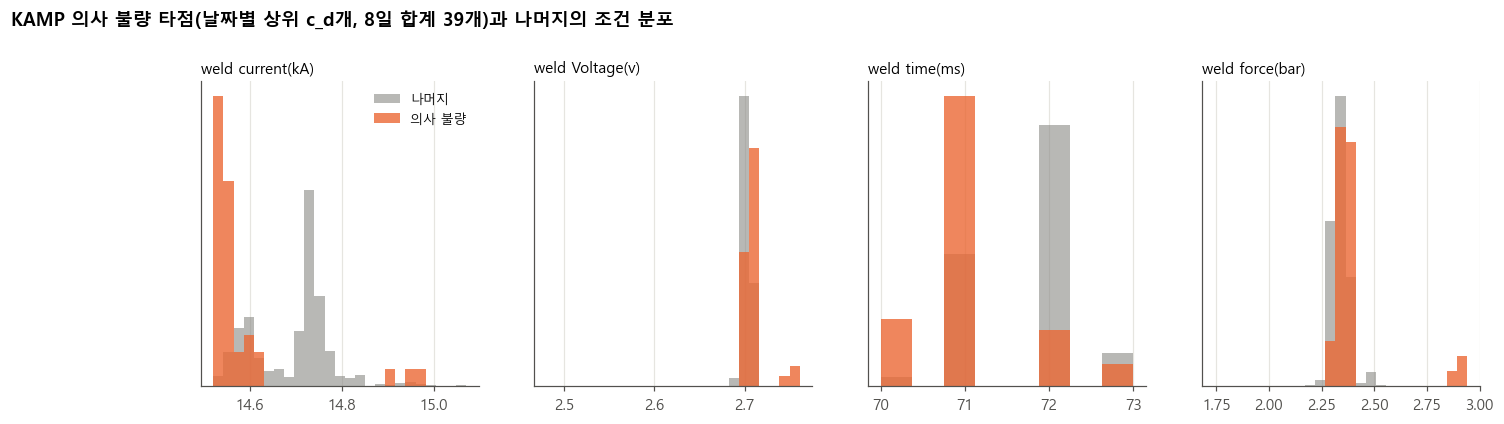

In [6]:
cols = ["weld current(kA)", "weld Voltage(v)", "weld time(ms)", "weld force(bar)"]
lab8 = out[(out.라벨근거 == "실제 일별 개수") & ~out.복사블록]
cmp_ = pd.DataFrame({"의사 불량": lab8[lab8["의사불량(하드)"] == 1][cols].mean(),
                     "후보 5배(의사 불량 제외)": lab8[(lab8.후보_5배 == 1) & (lab8["의사불량(하드)"] == 0)][cols].mean(),
                     "나머지": lab8[lab8.후보_5배 == 0][cols].mean()}).round(3)
display(cmp_)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(axes, cols):
    v0 = lab8[lab8.후보_5배 == 0][c]; v1 = lab8[lab8["의사불량(하드)"] == 1][c]
    bins = np.unique(np.r_[v0.values, v1.values]); bins = np.linspace(bins.min(), bins.max(), min(len(bins), 25) + 1)
    ax.hist(v0, bins=bins, density=True, color=P.GRAY, alpha=.6, label="나머지")
    ax.hist(v1, bins=bins, density=True, color=P.PAL[1], alpha=.8, label="의사 불량")
    ax.set_title(c, loc="left", fontsize=10); ax.set_yticks([])
axes[0].legend(fontsize=8.5)
fig.suptitle("KAMP 의사 불량 타점(날짜별 상위 c_d개, 8일 합계 39개)과 나머지의 조건 분포", x=0.01, y=1.06, ha="left", fontweight="bold")
P.save(fig, "11_kamp_pseudo_label_conditions"); plt.show()